# Del bloque al próximo token

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | La atención entrega un vector de contexto por token, pero un modelo de lenguaje tiene que terminar en otra cosa: un puntaje para cada palabra que podría seguir. |
| **Producto** | Un bloque Transformer calculado de punta a punta con números chicos y la lectura de su salida como una distribución sobre la próxima palabra. |
| **Recursos** | Python, NumPy y Matplotlib; no se descarga ni se entrena un modelo. |

En el cuaderno 02, cada token juntó contexto con atención causal. Pero GPT-2 no devuelve vectores de contexto: devuelve, para cada palabra de su vocabulario, qué tan probable es que venga después. Entre una cosa y la otra hay piezas del diagrama que todavía no abriste: varias cabezas, sumas residuales, normalización y una red feed-forward.

**¿Cómo se convierte el contexto que calcula la atención en una distribución de probabilidad sobre la palabra que sigue?**

> **Cómo se trabaja.** Primero explorás cada tema con el código ya escrito y las notas **Para mirar**. Al final hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import numpy as np

import utils

SEMILLA = 24
np.set_printoptions(precision=2, suppress=True)

print(f"numpy {np.__version__}")
print("La semilla fija los pesos al azar de este cuaderno; no los entrena.")

numpy 2.5.4
La semilla fija los pesos al azar de este cuaderno; no los entrena.


## 1. Una cabeza de atención, con todas sus piezas

Todos los números de este cuaderno son **inventados y sin entrenar**: muestran el mecanismo, no el comportamiento de un modelo de lenguaje.

En 02 usaste cada vector de entrada como consulta, clave y valor a la vez. Un modelo real los proyecta con tres matrices de pesos propias y divide los puntajes por la raíz del tamaño de la proyección. Además, cada token ya no tiene dos números sino cuatro: su embedding más un vector de posición, que armás con texto real en 012.

In [2]:
tokens = ["El", "archivo", "guarda", "datos"]
entradas = np.array([
    [0.20, 0.10, 0.60, 0.00],
    [0.90, 0.30, 0.10, 0.50],
    [0.70, 0.80, 0.20, 0.40],
    [0.30, 0.95, 0.50, 0.10],
])

print(f"forma de las entradas: {entradas.shape}")
print("una fila por token; cuatro numeros por token.")

forma de las entradas: (4, 4)
una fila por token; cuatro numeros por token.


In [3]:
def crear_pesos_del_bloque(semilla: int) -> dict:
    """Crea al azar los pesos de un bloque con dos cabezas.

    Args:
        semilla: Numero que fija el azar: la misma semilla da los mismos
            pesos.

    Returns:
        Diccionario con las matrices de cada pieza del bloque.
    """
    generador = np.random.default_rng(semilla)
    cabezas = []
    for numero_de_cabeza in range(2):
        cabezas.append({
            "consulta": generador.normal(size=(4, 2)),
            "clave": generador.normal(size=(4, 2)),
            "valor": generador.normal(size=(4, 2)),
        })
    return {
        "cabezas": cabezas,
        "union": generador.normal(size=(4, 4)),
        "ff_entrada": generador.normal(size=(4, 8)),
        "ff_salida": generador.normal(size=(8, 4)),
    }

pesos de atencion: (4, 4); contexto: (4, 2)


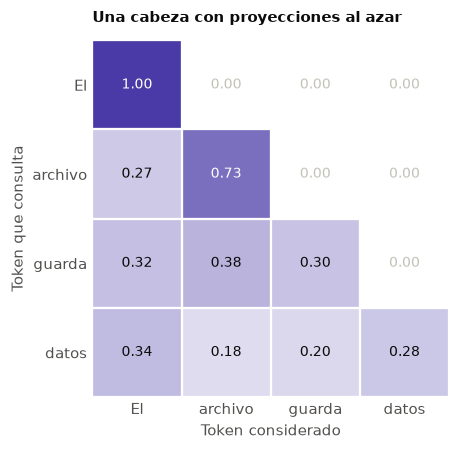

In [4]:
def atender(
    entradas: np.ndarray,
    w_consulta: np.ndarray,
    w_clave: np.ndarray,
    w_valor: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Calcula la atencion causal de una cabeza.

    Args:
        entradas: Un vector por token, uno por fila.
        w_consulta: Pesos que proyectan cada token a su consulta.
        w_clave: Pesos que proyectan cada token a su clave.
        w_valor: Pesos que proyectan cada token a su valor.

    Returns:
        Los pesos de atencion y el vector de contexto de cada token.
    """
    consultas = entradas @ w_consulta
    claves = entradas @ w_clave
    valores = entradas @ w_valor
    tamano = consultas.shape[1]
    puntajes = consultas @ claves.T / np.sqrt(tamano)
    for fila in range(len(puntajes)):
        puntajes[fila, fila + 1:] = -1e9
    pesos = utils.softmax(puntajes)
    return pesos, pesos @ valores


pesos_del_bloque = crear_pesos_del_bloque(semilla=SEMILLA)
cabeza_1 = pesos_del_bloque["cabezas"][0]
pesos_1, contexto_1 = atender(
    entradas, cabeza_1["consulta"], cabeza_1["clave"], cabeza_1["valor"]
)

print(f"pesos de atencion: {pesos_1.shape}; contexto: {contexto_1.shape}")
utils.dibujar_mapa_de_calor(
    matriz=pesos_1,
    filas=tokens,
    columnas=tokens,
    titulo="Una cabeza con proyecciones al azar",
    color=utils.VIOLETA,
)

> **Para mirar.**
>
> - Cada fila suma 1 y el futuro vale 0, igual que en 02. Lo nuevo es que los puntajes salen de tres proyecciones y se dividen por la raíz de 2, el tamaño de cada proyección.
> - Las proyecciones son números al azar: el patrón no significa nada todavía.

## 2. Por qué se divide por la raíz del tamaño

Un producto punto suma tantos términos como dimensiones tiene el vector. Con vectores grandes los puntajes crecen, y softmax se vuelve un interruptor: casi todo el peso cae en una sola clave y el resto casi no cuenta. Dividir por la raíz de `d` (el tamaño) mantiene los puntajes en una escala donde el reparto sigue siendo gradual.

Para verlo, una consulta y seis claves al azar, con tamaños cada vez más grandes.

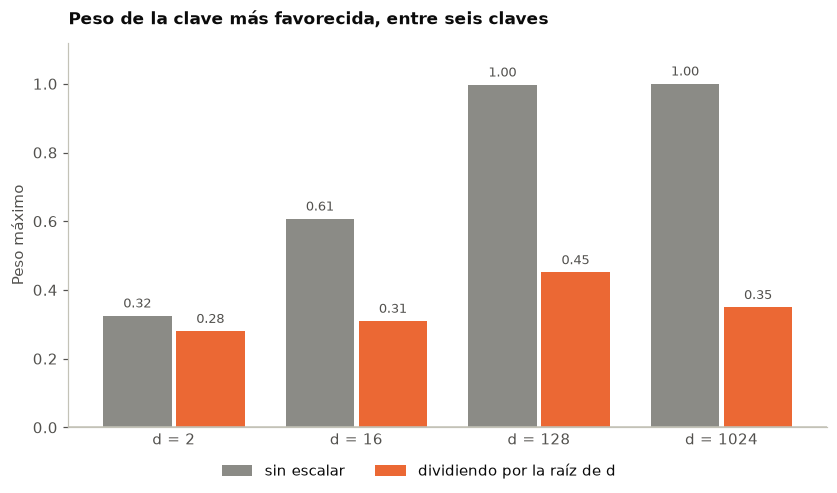

In [5]:
generador = np.random.default_rng(SEMILLA)
tamanos = [2, 16, 128, 1024]
rotulos = []
sin_escalar = []
escalando = []

for tamano in tamanos:
    consulta = generador.normal(size=tamano)
    claves = generador.normal(size=(6, tamano))
    puntajes = claves @ consulta
    sin_escalar.append(utils.softmax(puntajes).max())
    escalando.append(utils.softmax(puntajes / np.sqrt(tamano)).max())
    rotulos.append(f"d = {tamano}")

utils.dibujar_barras_agrupadas(
    categorias=rotulos,
    series={
        "sin escalar": sin_escalar,
        "dividiendo por la ra\u00edz de d": escalando,
    },
    titulo="Peso de la clave m\u00e1s favorecida, entre seis claves",
    etiqueta_y="Peso m\u00e1ximo",
)

> **Para mirar.** Sin escalar, el peso máximo se acerca a 1 a medida que crece `d`: una sola clave se lleva casi todo. Al dividir por la raíz de `d`, el peso máximo se mantiene entre 0,28 y 0,45 en todos los tamaños. Es una decisión de diseño que evita saturar softmax; no depende de los datos.

## 3. Varias cabezas, un solo vector

Una cabeza hace una sola pregunta por token. Un bloque hace varias a la vez, cada una con sus propias proyecciones, y pega los resultados lado a lado.

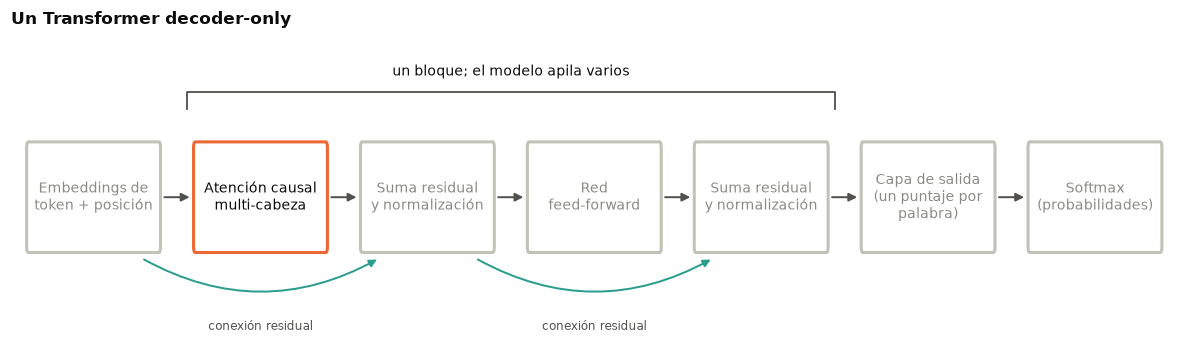

In [6]:
utils.dibujar_bloque_transformer(resaltar="atencion")

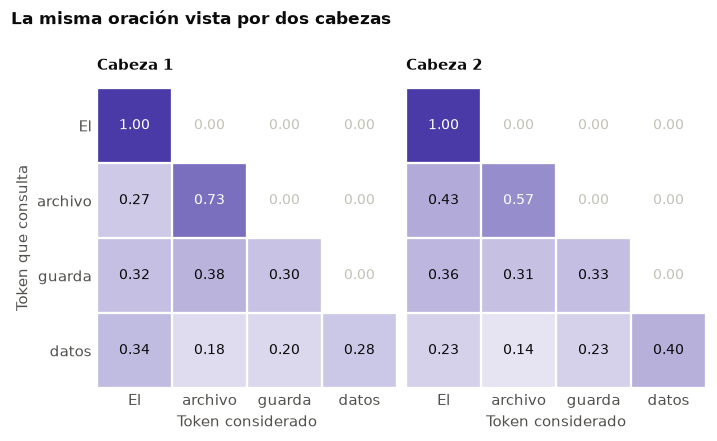

contextos unidos: (4, 4)


In [7]:
cabeza_2 = pesos_del_bloque["cabezas"][1]
pesos_2, contexto_2 = atender(
    entradas, cabeza_2["consulta"], cabeza_2["clave"], cabeza_2["valor"]
)

utils.dibujar_mapas_lado_a_lado(
    matrices={"Cabeza 1": pesos_1, "Cabeza 2": pesos_2},
    filas=tokens,
    columnas=tokens,
    titulo="La misma oraci\u00f3n vista por dos cabezas",
    color=utils.VIOLETA,
)

# axis=1 pega los contextos lado a lado: dos numeros de cada cabeza.
contextos_unidos = np.concatenate([contexto_1, contexto_2], axis=1)
print(f"contextos unidos: {contextos_unidos.shape}")

> **Para mirar.**
>
> - Con la misma oración, las dos cabezas reparten el peso distinto porque sus proyecciones son distintas.
> - Al pegar los dos contextos, cada token vuelve a tener cuatro números: el mismo tamaño con el que entró.
> - Con pesos entrenados, cada cabeza tiende a especializarse. En el cuaderno 04 lo medís en un modelo real.

## 4. Sumar, normalizar y transformar cada token

Tres piezas más completan el bloque.

- **Suma residual:** al vector de entrada se le suma lo que calculó la atención, así no se pierde lo que el token ya traía.
- **Normalización:** reescala cada vector a media cero y desvío uno, para que los números no crezcan de bloque en bloque.
- **Red feed-forward:** transforma cada vector por separado. Es la única pieza donde los tokens no se miran entre sí.

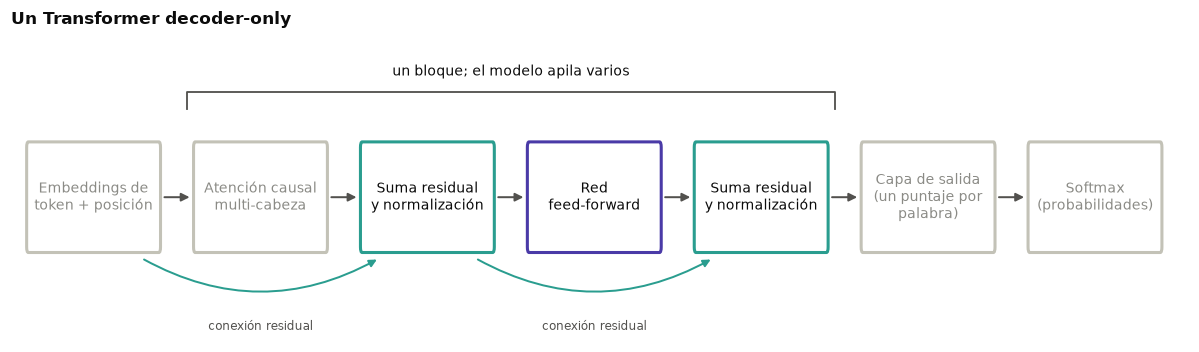

In [8]:
utils.dibujar_bloque_transformer(resaltar=("residual", "feed-forward"))

In [9]:
def normalizar(vectores: np.ndarray) -> np.ndarray:
    """Deja cada vector con media cero y desvio uno.

    Args:
        vectores: Un vector por fila.

    Returns:
        Los vectores normalizados, con la misma forma.
    """
    # keepdims=True conserva la forma para poder restar fila por fila.
    medias = vectores.mean(axis=1, keepdims=True)
    desvios = vectores.std(axis=1, keepdims=True)
    return (vectores - medias) / (desvios + 1e-5)


def red_feed_forward(
    vectores: np.ndarray, w_entrada: np.ndarray, w_salida: np.ndarray
) -> np.ndarray:
    """Transforma cada vector con dos capas lineales y un filtro.

    Args:
        vectores: Un vector por fila.
        w_entrada: Pesos de la primera capa, que ensancha el vector.
        w_salida: Pesos de la segunda capa, que lo vuelve a angostar.

    Returns:
        Un vector transformado por fila.
    """
    ensanchados = vectores @ w_entrada
    # np.maximum(.., 0) deja pasar solo los valores positivos.
    filtrados = np.maximum(ensanchados, 0.0)
    return filtrados @ w_salida

entra al bloque: (4, 4); sale: (4, 4)


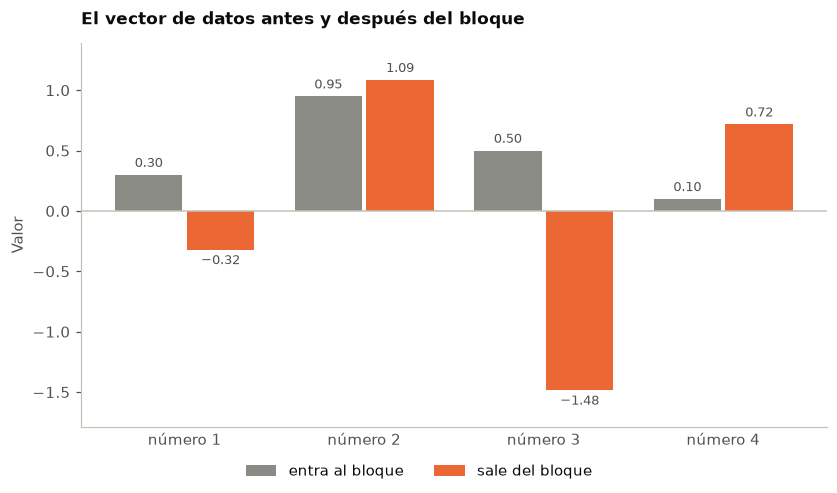

In [10]:
salida_de_atencion = contextos_unidos @ pesos_del_bloque["union"]
tras_atencion = normalizar(entradas + salida_de_atencion)

salida_feed_forward = red_feed_forward(
    tras_atencion,
    pesos_del_bloque["ff_entrada"],
    pesos_del_bloque["ff_salida"],
)
salida_del_bloque = normalizar(tras_atencion + salida_feed_forward)

print(f"entra al bloque: {entradas.shape}; sale: {salida_del_bloque.shape}")
utils.dibujar_barras_agrupadas(
    categorias=[
        "n\u00famero 1", "n\u00famero 2",
        "n\u00famero 3", "n\u00famero 4",
    ],
    series={
        "entra al bloque": entradas[3],
        "sale del bloque": salida_del_bloque[3],
    },
    titulo="El vector de datos antes y despu\u00e9s del bloque",
    etiqueta_y="Valor",
)

> **Para mirar.**
>
> - Entra una matriz de cuatro vectores de cuatro números y sale otra de la misma forma. Por eso los bloques se pueden apilar: la salida de uno es la entrada del siguiente.
> - Los números cambiaron, y no por una regla que se pueda leer: los pesos son al azar.

Los pasos de arriba se encapsulan en una función, con las mismas piezas y en el mismo orden.

In [11]:
def aplicar_bloque(entradas: np.ndarray, pesos: dict) -> np.ndarray:
    """Aplica un bloque Transformer decoder-only a una secuencia.

    Args:
        entradas: Un vector de cuatro numeros por token.
        pesos: Pesos del bloque, como los crea crear_pesos_del_bloque.

    Returns:
        Un vector de cuatro numeros por token, con la misma forma.
    """
    contextos = []
    for cabeza in pesos["cabezas"]:
        _, contexto = atender(
            entradas, cabeza["consulta"], cabeza["clave"], cabeza["valor"]
        )
        contextos.append(contexto)
    unidos = np.concatenate(contextos, axis=1)
    tras_atencion = normalizar(entradas + unidos @ pesos["union"])
    transformados = red_feed_forward(
        tras_atencion, pesos["ff_entrada"], pesos["ff_salida"]
    )
    return normalizar(tras_atencion + transformados)


mismo_resultado = np.allclose(
    aplicar_bloque(entradas, pesos_del_bloque), salida_del_bloque
)
print(f"la funcion da lo mismo que los pasos sueltos: {mismo_resultado}")

la funcion da lo mismo que los pasos sueltos: True


## 5. Apilar bloques y llegar al vocabulario

GPT-2 apila bloques. Después del último, una **capa de salida** multiplica el vector del último token por una matriz con una columna por palabra del vocabulario. Cada resultado es un puntaje, o **logit**, y softmax los convierte en probabilidades. Se usa el último token porque, con la máscara causal, es el único que vio toda la oración.

Acá el vocabulario tiene seis palabras y el modelo, dos bloques.

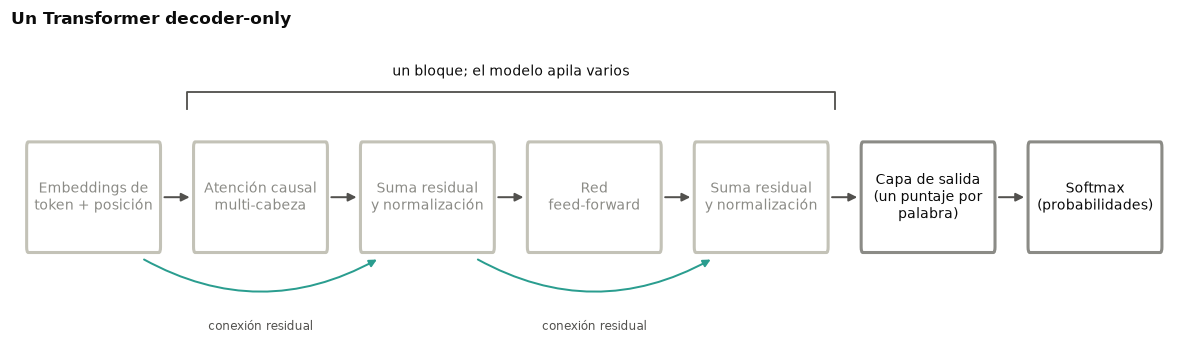

In [12]:
utils.dibujar_bloque_transformer(resaltar="salida")

logits: [-1.31  1.14  2.06  0.49 -0.59  3.5 ]
suman: 1.00


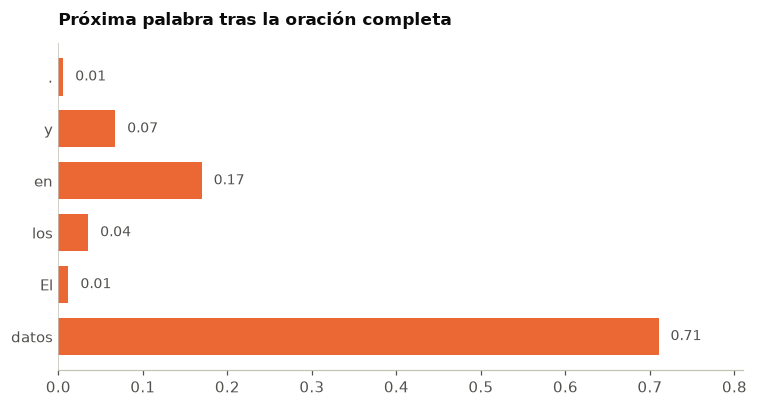

In [13]:
vocabulario = [".", "y", "en", "los", "El", "datos"]

bloque_1 = crear_pesos_del_bloque(semilla=SEMILLA)
bloque_2 = crear_pesos_del_bloque(semilla=SEMILLA + 1)
generador_de_salida = np.random.default_rng(SEMILLA + 2)
matriz_de_salida = generador_de_salida.normal(size=(4, len(vocabulario)))

tras_bloque_1 = aplicar_bloque(entradas, bloque_1)
tras_bloque_2 = aplicar_bloque(tras_bloque_1, bloque_2)

logits_datos = tras_bloque_2[-1] @ matriz_de_salida
probabilidades_datos = utils.softmax(logits_datos)

print(f"logits: {logits_datos}")
print(f"suman: {probabilidades_datos.sum():.2f}")
utils.dibujar_barras(
    nombres=vocabulario,
    valores=probabilidades_datos,
    titulo="Pr\u00f3xima palabra tras la oraci\u00f3n completa",
    color=utils.NARANJA,
)

> **Para mirar.** Salió una distribución completa, con una palabra más probable que las demás. Que tenga esa forma no la vuelve una buena predicción: el modelo propone `datos` después de `datos` porque los pesos son al azar, no porque haya aprendido algo del español.

### Microlaboratorio 1 — La próxima palabra después de «El archivo»

**Tarea.** Repetí la capa de salida con el vector del segundo token, sin repetir el resto del cálculo.  
**Producto.** Las probabilidades del vocabulario después de «El archivo» y la palabra elegida.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) | el vector de `archivo` al salir del segundo bloque | `tras_bloque_2` indexada por la posición del token (la primera fila es la 0) |
| (2) | un puntaje por palabra del vocabulario | el producto `@` entre ese vector y `matriz_de_salida` |
| (3) | las probabilidades | `utils.softmax` aplicada a los puntajes |
| (4) | la posición de la palabra más probable | `np.argmax` de las probabilidades, convertida con `int` |

> **Ayuda 1.** En la sección 5, el último token se toma con `tras_bloque_2[-1]`: acá necesitás otra fila.  
> **Ayuda 2.** Las líneas (2) y (3) son las mismas de la sección 5, con otro vector.

In [14]:
vector_archivo = np.zeros(4)  # COMPLETAR (1)
logits_archivo = np.zeros(len(vocabulario))  # COMPLETAR (2)
probabilidades_archivo = np.zeros(len(vocabulario))  # COMPLETAR (3)
posicion_elegida = 0  # COMPLETAR (4)

print(f"despues de 'El archivo': {vocabulario[posicion_elegida]}")
utils.comprobar(
    np.isclose(probabilidades_archivo.sum(), 1.0)
    and not np.allclose(logits_archivo, logits_datos)
    and posicion_elegida == int(np.argmax(probabilidades_archivo)),
    "revisa (1) a (4): las probabilidades suman 1 y salen de archivo.",
)

despues de 'El archivo': .
Todavia no. revisa (1) a (4): las probabilidades suman 1 y salen de archivo.


## 6. Donde el mecanismo no alcanza

El mecanismo es el mismo en cualquier Transformer decoder-only. Lo que cambia entre un modelo y otro son los pesos. Para verlo, la misma oración con tres juegos de pesos al azar.

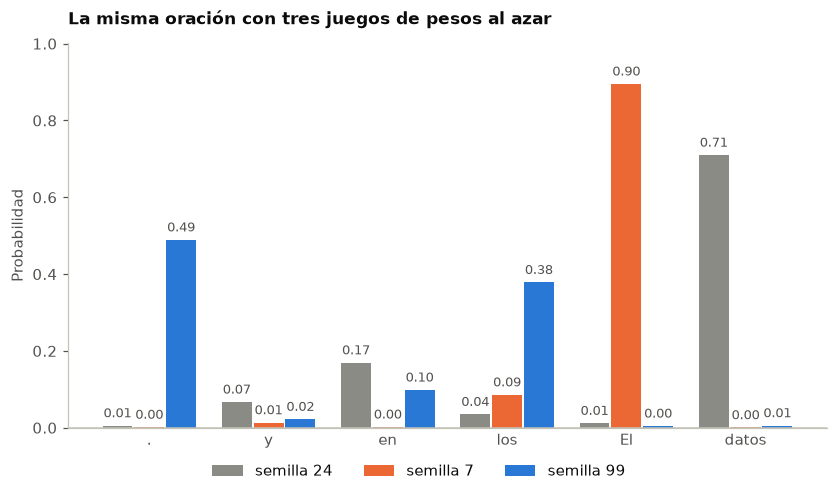

In [15]:
def predecir_proximo_token(semilla: int) -> np.ndarray:
    """Calcula las probabilidades del proximo token con pesos al azar.

    Args:
        semilla: Numero que fija todos los pesos del modelo.

    Returns:
        Una probabilidad por palabra del vocabulario.
    """
    primero = crear_pesos_del_bloque(semilla)
    segundo = crear_pesos_del_bloque(semilla + 1)
    generador = np.random.default_rng(semilla + 2)
    salida = generador.normal(size=(4, len(vocabulario)))
    vector_final = aplicar_bloque(aplicar_bloque(entradas, primero), segundo)
    return utils.softmax(vector_final[-1] @ salida)


series = {}
for semilla in [SEMILLA, 7, 99]:
    series[f"semilla {semilla}"] = predecir_proximo_token(semilla)

utils.dibujar_barras_agrupadas(
    categorias=vocabulario,
    series=series,
    titulo="La misma oraci\u00f3n con tres juegos de pesos al azar",
    etiqueta_y="Probabilidad",
)

> **Para mirar.**
>
> - Con la misma oración y el mismo mecanismo, cada juego de pesos propone una palabra distinta.
> - Lo que sabe un modelo de lenguaje está en sus pesos, no en el mecanismo. Por eso en 010 ajustar BETO cambió sus respuestas sin cambiar su arquitectura.
> - Una distribución bien formada no es una salida adecuada.

**Decisión de uso.** Este bloque sirve para ver cómo se llega de un contexto a una distribución sobre palabras. No sirve para predecir texto: sin entrenamiento, la palabra elegida no tiene relación con la oración.

## Qué te llevás

- Un bloque combina varias cabezas de atención, suma residual, normalización y una red feed-forward, y devuelve vectores del mismo tamaño que recibió.
- Al final, una capa de salida da un puntaje por palabra y softmax lo convierte en probabilidades: esa es la distribución del próximo token.
- El mecanismo no distingue un buen modelo de uno inútil: la diferencia está en los pesos.

**Sigue:** el cuaderno 04 abre un modelo real, BETO, y mide qué hacen sus cabezas de atención sobre dos versos del *Martín Fierro*.